## **ASSIGNMENT: GROUP K**

<div style="text-align: justify">
This assignment will serve as an analysis of a dataset of NYC yellow and green taxi trips from January through March 18th. The data, which was collected by TLC-authorized providers, includes pick-up/drop-off times and locations, trip distances, fare details, payment methods and passenger counts.<br>

The four studies that will be conducted on this data are the following:
- **Study 1**: Average speed of taxis in terms of the hour.
- **Study 2**: Most common taxi trips.
- **Study 3**: Average tip per zone.
- **Study 4**: Average distance per number of passengers.

Each study will be implemented in three ways: using RDDs, SQL and DataFrames. For each implementation, execution time, amount of processed data and the resulting processing speed will be reported. 
</div>

In [ ]:
from pyspark.sql import SparkSession
from pyspark import SparkContext, SparkConf
from pyspark.sql.functions import *
import time
import seaborn as sns
import matplotlib.pyplot as plt
from datetime import datetime
import numpy as np
import pandas as pd

spark = SparkSession.builder.master('local[8]').getOrCreate()

sc = spark.sparkContext
spark

The first step is to clean the dataset. This involves removing records with no passengers, zero distance or payment, and negative distances.

In [3]:
df = spark.read.format("parquet").option("inferSchema", "true").option("timestampFormat","yyyy-MM-dd HH:mm:ss").option("header", "true").option("mode", "DROPMALFORMED").load("yellow_tripdata_2025-01.parquet")
df = df.filter((df["passenger_count"] > 0) & (df["trip_distance"] > 0) & (df["fare_amount"] > 0) & (df["tip_amount"] >= 0))
df.show()

AnalysisException: [PATH_NOT_FOUND] Path does not exist: file:/c:/Users/dlgch/Desktop/UC3M/highFreq/Lab-Spark/yellow_tripdata_2025-01.parquet. SQLSTATE: 42K03

## **Study 1: Average speed of taxis in terms of the hour**

## RDDs 

In [ ]:
# 1. Get total row count.
s1_rdd = df.count()

# 2. Convert DataFrame to RDD.
rdd_s1 = df.rdd

# 3. Define the function for calculating the average speed in each hour.
def speed_computation(row):
    PU_time = row['tpep_pickup_datetime']
    DO_time = row['tpep_dropoff_datetime']
    
    # Calculate duration in hours.
    trip_time = (DO_time - PU_time).total_seconds() / 3600.0
    
    # Filter: Only process trips with a positive duration.
    if trip_time > 0:
        # Calculate speed in miles/h.
        speed = row['trip_distance'] / trip_time
        hour = PU_time.hour
        
        # Return a key-value pair: (hour, (speed, 1_trip))
        return (hour, (speed, 1))
    else:
        return None

# 4. Map, Filter, and Reduce.
#    a) Apply the function to all rows and filter out the 'None' values.
speed_computation_rdd = rdd_s1.map(speed_computation).filter(lambda x: x is not None)

#    b) Aggregate by key (hour) to get (TotalSpeedSum, TotalTripCount).
average_speed_computation = speed_computation_rdd \
    .reduceByKey(lambda x, y: (x[0] + y[0], x[1] + y[1]))

# 5. Calculate the final average (TotalSpeedSum / TotalTripCount).
average_speed_computation = average_speed_computation.mapValues(lambda x: x[0] / x[1])

# 6. Sort by hour and format the key.
average_speed_computation_ordered = average_speed_computation.sortByKey().map(lambda x: (f'{x[0]}:00', x[1]))

# 7. Convert the final RDD back to a DataFrame.
df_s1_rdd = average_speed_computation_ordered.toDF(['Hour', 'Average Speed (miles/h)'])
df_s1_rdd = df_s1_rdd.withColumn('Average Speed (miles/h)', round(df_s1_rdd['Average Speed (miles/h)'], 2))

# 8. Trigger the job and measure the time.
start_time_s1_rdd = time.time()
df_s1_rdd.show()
end_time_s1_rdd = time.time() 

# 9. Calculate and print performance metrics.
execution_time_s1_rdd = end_time_s1_rdd - start_time_s1_rdd
processing_speed_s1_rdd = s1_rdd / execution_time_s1_rdd

print(f"--- Study 1 (RDD) Performance Metrics ---")
print(f"Execution Time: {execution_time_s1_rdd:.4f} seconds")
print(f"Amount of Processed Data: {s1_rdd} rows")
print(f"Processing Speed: {processing_speed_s1_rdd:.2f} rows/second")

+-----+-----------------------+
| Hour|Average Speed (miles/h)|
+-----+-----------------------+
| 0:00|                  15.27|
| 1:00|                  14.92|
| 2:00|                  14.01|
| 3:00|                  15.19|
| 4:00|                  18.94|
| 5:00|                   20.0|
| 6:00|                  17.19|
| 7:00|                   12.9|
| 8:00|                  10.99|
| 9:00|                  11.08|
|10:00|                  10.89|
|11:00|                  10.33|
|12:00|                  10.44|
|13:00|                  10.88|
|14:00|                  10.34|
|15:00|                  10.44|
|16:00|                  10.38|
|17:00|                  10.01|
|18:00|                  10.31|
|19:00|                   11.7|
+-----+-----------------------+
only showing top 20 rows
--- Study 1 (RDD) Performance Metrics ---
Execution Time: 0.2225 seconds
Amount of Processed Data: 2816835 rows
Processing Speed: 12658096.60 rows/second


## SQL 

In [ ]:
# 1. Get total row count.
s1_sql = df.count()

# 2. Create temporary view for SQL queries.
df.createOrReplaceTempView("df")

# 3. Define SQL query to calculate average speed per hour.
query = """
    SELECT hour(tpep_pickup_datetime) AS Hour, 
           AVG(trip_distance / (unix_timestamp(tpep_dropoff_datetime) - unix_timestamp(tpep_pickup_datetime)) * 3600) AS AverageSpeed
    FROM df
    WHERE unix_timestamp(tpep_dropoff_datetime) > unix_timestamp(tpep_pickup_datetime)
    GROUP BY hour(tpep_pickup_datetime)
    ORDER BY Hour
"""

# 4. Execute the SQL query.
df_s1_sql = spark.sql(query)

# 5. Format the result: adjust Hour column, round speed values, and rename column.
df_s1_sql = df_s1_sql.withColumn("Hour", concat(df_s1_sql["Hour"].cast("string"), lit(":00"))) \
                     .withColumn("AverageSpeed", round(df_s1_sql["AverageSpeed"], 2)) \
                     .withColumnRenamed("AverageSpeed", "Average Speed (miles/h)")

# 6. Trigger the job and measure the time.
start_time_s1_sql = time.time()
df_s1_sql.show()
end_time_s1_sql = time.time()

# 7. Calculate and print performance metrics.
execution_time_s1_sql = end_time_s1_sql - start_time_s1_sql
processing_speed_s1_sql = s1_sql / execution_time_s1_sql

print(f"--- Study 1 (SQL) Performance Metrics ---")
print(f"Execution Time: {execution_time_s1_sql:.4f} seconds")
print(f"Amount of Processed Data: {s1_sql} rows")
print(f"Processing Speed: {processing_speed_s1_sql:.2f} rows/second")

+-----+-----------------------+
| Hour|Average Speed (miles/h)|
+-----+-----------------------+
| 0:00|                  15.27|
| 1:00|                  14.92|
| 2:00|                  14.01|
| 3:00|                  15.19|
| 4:00|                  18.94|
| 5:00|                   20.0|
| 6:00|                  17.19|
| 7:00|                   12.9|
| 8:00|                  10.99|
| 9:00|                  11.08|
|10:00|                  10.89|
|11:00|                  10.33|
|12:00|                  10.44|
|13:00|                  10.88|
|14:00|                  10.34|
|15:00|                  10.44|
|16:00|                  10.38|
|17:00|                  10.01|
|18:00|                  10.31|
|19:00|                   11.7|
+-----+-----------------------+
only showing top 20 rows
--- Study 1 (SQL) Performance Metrics ---
Execution Time: 0.5091 seconds
Amount of Processed Data: 2816835 rows
Processing Speed: 5533255.42 rows/second


## DataFrames

In [ ]:
# 1. Get total row count.
s1_df = df.count()

# 2. Add trip duration column and calculate speed and filter out trips with zero or negative duration.
df_s1 = df.withColumn("TripDuration", (unix_timestamp("tpep_dropoff_datetime") - unix_timestamp("tpep_pickup_datetime")) / 3600) \
              .filter(col("TripDuration") > 0) \
              .withColumn("Speed", col("trip_distance") / col("TripDuration"))

# 3. Group by pickup hour and calculate average speed.
df_s1_df = df_s1.withColumn("Hour", hour("tpep_pickup_datetime")) \
                    .groupBy("Hour") \
                    .avg("Speed") \
                    .withColumnRenamed("avg(Speed)", "AverageSpeed")

# 4. Convert average speed to float type.
df_s1_df = df_s1_df.withColumn("AverageSpeed", col("AverageSpeed").cast("float"))

# 5. Order by hour and format the results.
df_s1_df = df_s1_df.orderBy("Hour") \
                   .withColumn("AverageSpeed", round(col("AverageSpeed"), 2)) \
                   .withColumnRenamed("AverageSpeed", "Average Speed (miles/h)") \
                   .withColumn("Hour", concat(col("Hour").cast("string"), lit(":00")))

# 6. Trigger the job and measure the time.
start_time_s1_df = time.time()
df_s1_df.show()
end_time_s1_df = time.time()

# 7. Calculate and print performance metrics.
execution_time_s1_df = end_time_s1_df - start_time_s1_df
processing_speed_s1_df = s1_df / execution_time_s1_df

print(f"--- Study 1 (DataFrames) Performance Metrics ---")
print(f"Execution Time: {execution_time_s1_df:.4f} seconds")
print(f"Amount of Processed Data: {s1_df} rows")
print(f"Processing Speed: {processing_speed_s1_df:.2f} rows/second")

+-----+-----------------------+
| Hour|Average Speed (miles/h)|
+-----+-----------------------+
| 0:00|                  15.27|
| 1:00|                  14.92|
| 2:00|                  14.01|
| 3:00|                  15.19|
| 4:00|                  18.94|
| 5:00|                   20.0|
| 6:00|                  17.19|
| 7:00|                   12.9|
| 8:00|                  10.99|
| 9:00|                  11.08|
|10:00|                  10.89|
|11:00|                  10.33|
|12:00|                  10.44|
|13:00|                  10.88|
|14:00|                  10.34|
|15:00|                  10.44|
|16:00|                  10.38|
|17:00|                  10.01|
|18:00|                  10.31|
|19:00|                   11.7|
+-----+-----------------------+
only showing top 20 rows
--- Study 1 (DataFrames) Performance Metrics ---
Execution Time: 0.2970 seconds
Amount of Processed Data: 2816835 rows
Processing Speed: 9483998.20 rows/second


<div style="text-align: justify">
The performance comparison of the three methods reveals that the RDD approach is consistently the fastest, followed by DataFrames, while SQL is the slowest. All methods show similar performance levels, with RDDs maintaining a clear advantage in processing speed across all tests.
</div>

### Execution time and speed-up vs number of cores

In [ ]:
# Define the number of cores and execution times for each method.
cores = np.array([1, 2, 3, 4, 5])
time_rdd = np.array([0.1168, 0.1043, 0.1037, 0.1034, 0.1066])
time_sql = np.array([0.3893, 0.1720, 0.1474, 0.1423, 0.1457])   
time_df = np.array([0.3173, 0.1836, 0.1492, 0.1465, 0.1478])  

time_core = pd.DataFrame({
    'cores': cores,
    'time_rdd': time_rdd,
    'time_sql': time_sql, 
    'time_df': time_df
})

print(time_core)

   cores  time_rdd  time_sql  time_df
0      1    0.1168    0.3893   0.3173
1      2    0.1043    0.1720   0.1836
2      3    0.1037    0.1474   0.1492
3      4    0.1034    0.1423   0.1465
4      5    0.1066    0.1457   0.1478


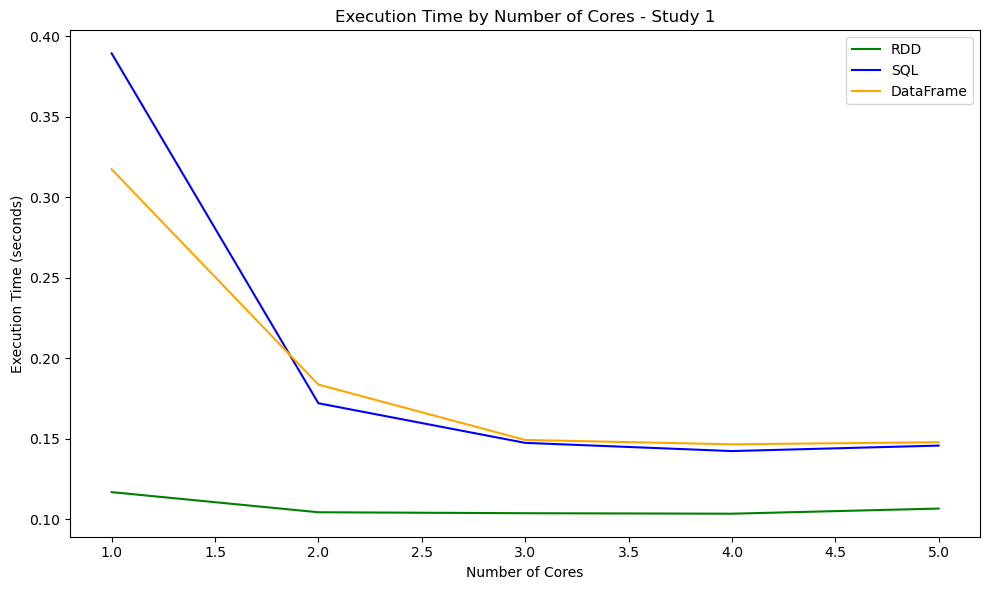

In [ ]:
# Create the plot of the execution time scaling from 1 to 5 cores.
fig, ax = plt.subplots(figsize=(10, 6))

sns.lineplot(x='cores', y='time_rdd', data=time_core, ax=ax, color='green', label='RDD')
sns.lineplot(x='cores', y='time_sql', data=time_core, ax=ax, color='blue', label='SQL')
sns.lineplot(x='cores', y='time_df', data=time_core, ax=ax, color='orange', label='DataFrame')

ax.set_xlabel("Number of Cores")
ax.set_ylabel("Execution Time (seconds)")
ax.set_title("Execution Time by Number of Cores - Study 1")
ax.tick_params(axis='x', rotation=0)
ax.legend()
fig.tight_layout()

plt.show()

<div style="text-align: justify">
The performance analysis across different core configurations reveals that RDDs consistently achieve the fastest execution times, maintaining their advantage regardless of the number of cores utilized. <br>

All three methods demonstrate significant performance improvements with additional cores, with optimal performance reached at 4 cores for each approach. SQL queries show the most substantial scalability benefit while RDDs demonstrates a more modest enhancement. Beyond 4 cores, performance slightly degrades for all methods, indicating the optimal balance between parallelization benefits and coordination overhead.
</div>


In [ ]:
# 1. Create an empty DataFrame to store the speed-up by core.
df_speed_up = pd.DataFrame()
df_speed_up['cores'] = time_core['cores']

# 2. Calculate the speed-up for each method compared to single-core performance.
for column in time_core.drop(columns='cores'):
    one_core_time = time_core[time_core['cores'] == 1][column].values[0]

    # Compute speed-up ratio: time with 1 core / time with N cores.
    speed_up_values = time_core[column].apply(lambda x: one_core_time / x)
    
    df_speed_up[column] = speed_up_values

print(df_speed_up)

   cores  time_rdd  time_sql   time_df
0      1  1.000000  1.000000  1.000000
1      2  1.119847  2.263372  1.728214
2      3  1.126326  2.641113  2.126676
3      4  1.129594  2.735770  2.165870
4      5  1.095685  2.671929  2.146820


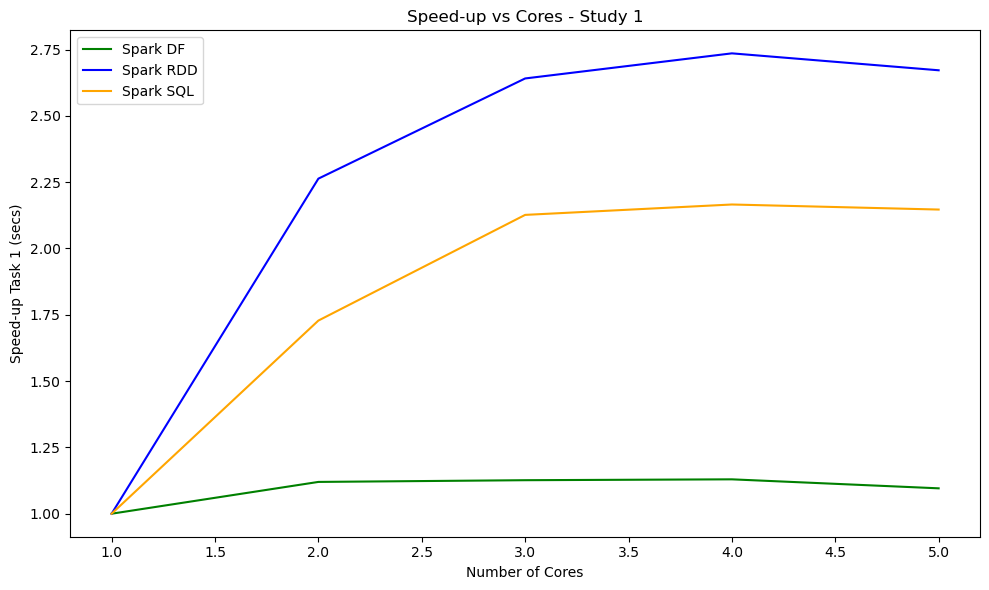

In [ ]:
# Create the plot of the speed-up scaling from 1 to 5 cores
fig, ax = plt.subplots(figsize=(10, 6))

sns.lineplot(x='cores', y='time_rdd', data=df_speed_up, ax=ax, color='green', label='Spark DF')
sns.lineplot(x='cores', y='time_sql', data=df_speed_up, ax=ax, color='blue', label='Spark RDD')
sns.lineplot(x='cores', y='time_df', data=df_speed_up, ax=ax, color='orange', label='Spark SQL')

ax.set_xlabel("Number of Cores")
ax.set_ylabel("Speed-up Task 1 (secs)")
ax.set_title("Speed-up vs Cores - Study 1")

ax.tick_params(axis='x', rotation=0)
ax.legend()
plt.tight_layout()
plt.show()

<div style="text-align: justify">
Analysis shows SQL achieves the highest speed-up (x2.74 with 4 cores), followed by DataFrames (x2.17), while RDDs show modest improvement (x1.13). This indicates SQL and DataFrames benefit more from parallelization, though RDDs maintain the best absolute performance across all configurations.
</div>

## **Study 2: Most common taxi trips**

## RDDs

In [ ]:
# 1. First, the data needs to be prepared for using RDDs
# From the taxi Trip record data, we are going to use the Taxi Lookup Zone Table (csv)
# The format of the time is changed
# We filter the zone to delete NAs rows
zones_df = spark.read.format("csv").option("inferSchema", "true").option("timestampFormat","yyyy-MM-dd HH:mm:ss").option("header", "true").option("mode", "DROPMALFORMED").load("taxi_zone_lookup.csv")
zones_df = zones_df.filter(zones_df['Zone'] != 'N/A')

s2_1_rdd = df.count()
s2_2_rdd = zones_df.count()

rdd_s2_1 = df.rdd
rdd_s2_2 = zones_df.rdd

# 2. Now, we do a Map of LocationID and Zone, and another map for PULocationID and DOLocationID.
zone_rdd = rdd_s2_2.map(lambda row: (row['LocationID'], row['Zone']))
trip_rdd = rdd_s2_1.map(lambda row: ((row['PULocationID'], row['DOLocationID']), 1))

# 3. In order to count the number of trips for each pickup and dropoff pair, we do a reduceByKey of the trips
trip_counts = trip_rdd.reduceByKey(lambda a, b: a + b)

# 4. We change the key to PULocation for joining with zones.
pu_join = trip_counts.map(lambda x: (x[0][0], (x[0][1], x[1]))).join(zone_rdd)

# 5. Now, reformat to (DOLocationID, (PickupZone, Count)).
trip_names_rdd = pu_join.map(lambda x: (x[1][0][0], (x[1][1], x[1][0][1]))).join(zone_rdd)
trip_names_rdd = trip_names_rdd.map(lambda x: (x[1][0][0], x[1][1], x[1][0][1]))

#  6. To find the most popular trips, we sort the RDD by count in descending order.
top_trips = trip_names_rdd.sortBy(lambda x: x[2], ascending=False)

# 7. Convert the RDD to a DataFrame to display the top trips with pickup and dropoff zone names.
df_s2_rdd = top_trips.toDF(["PickupZone", "DropoffZone", "Count"])

start_time_s2_rdd = time.time()
df_s2_rdd.show()
end_time_s2_rdd = time.time()

# 8. Calculate and print the execution time, data processed and processing speed.
execution_time_s2_rdd = end_time_s2_rdd - start_time_s2_rdd
s2_rdd = s2_1_rdd + s2_2_rdd
processing_speed_s2_rdd = s2_rdd / execution_time_s2_rdd
print(f"Execution Time: {execution_time_s2_rdd} seconds")
print(f"Amount of Processed Data: {s2_rdd} rows")
print(f"Processing Speed: {processing_speed_s2_rdd} rows/second")

+--------------------+--------------------+-----+
|          PickupZone|         DropoffZone|Count|
+--------------------+--------------------+-----+
|Upper East Side S...|Upper East Side N...|23456|
|Upper East Side N...|Upper East Side S...|20262|
|Upper East Side N...|Upper East Side N...|16401|
|Upper East Side S...|Upper East Side S...|15631|
|      Midtown Center|Upper East Side S...|10711|
|Upper East Side S...|      Midtown Center| 9367|
|      Midtown Center|Upper East Side N...| 9153|
|Upper West Side S...|Upper West Side N...| 8875|
| Lincoln Square East|Upper West Side S...| 8568|
|Upper West Side S...| Lincoln Square East| 8055|
|     Lenox Hill West|Upper East Side N...| 8000|
|Penn Station/Madi...|Times Sq/Theatre ...| 7936|
|Upper East Side N...|     Lenox Hill West| 7443|
|Upper East Side S...|     Lenox Hill West| 7323|
|Upper East Side S...|        Midtown East| 7315|
|Upper East Side N...|      Midtown Center| 7158|
|Upper West Side N...|Upper West Side S...| 7116|


## SQL

In [ ]:
# 1. In order to obtain the top 10 taxis by querying, we need first to prepare the data.
df.createOrReplaceTempView("trips")
zones_df.createOrReplaceTempView("zones")
s1_2_sql = df.count()
s2_sql = zones_df.count()

# 2. SQL query: JOIN and COUNT the trips.
query = """SELECT pickup_zones.Zone AS PickupZone,
        dropoff_zones.Zone AS DropoffZone,
        COUNT(*) AS Count
        FROM trips
        JOIN zones AS pickup_zones ON trips.PULocationID = pickup_zones.LocationID
        JOIN zones AS dropoff_zones ON trips.DOLocationID = dropoff_zones.LocationID
        GROUP BY PickupZone, DropoffZone
        ORDER BY Count DESC
        LIMIT 20"""

# 3. Execute the SQL query
df_s2_sql = spark.sql(query)

# 4. Calculate and print performance metrics.
start_time_s2_sql = time.time()
df_s2_sql.show()
end_time_s2_sql = time.time()

execution_time_s2_sql = end_time_s2_sql - start_time_s2_sql
s2_sql = s1_2_sql+ s2_sql
processing_speed_s2_sql = s2_sql / execution_time_s2_sql
print(f"Execution Time: {execution_time_s2_sql} seconds")
print(f"Amount of Processed Data: {s2_sql} rows")
print(f"Processing Speed: {processing_speed_s2_sql} rows/second")

+--------------------+--------------------+-----+
|          PickupZone|         DropoffZone|Count|
+--------------------+--------------------+-----+
|Upper East Side S...|Upper East Side N...|23456|
|Upper East Side N...|Upper East Side S...|20262|
|Upper East Side N...|Upper East Side N...|16401|
|Upper East Side S...|Upper East Side S...|15631|
|      Midtown Center|Upper East Side S...|10711|
|Upper East Side S...|      Midtown Center| 9367|
|      Midtown Center|Upper East Side N...| 9153|
|Upper West Side S...|Upper West Side N...| 8875|
| Lincoln Square East|Upper West Side S...| 8568|
|Upper West Side S...| Lincoln Square East| 8055|
|     Lenox Hill West|Upper East Side N...| 8000|
|Penn Station/Madi...|Times Sq/Theatre ...| 7936|
|Upper East Side N...|     Lenox Hill West| 7443|
|Upper East Side S...|     Lenox Hill West| 7323|
|Upper East Side S...|        Midtown East| 7315|
|Upper East Side N...|      Midtown Center| 7158|
|Upper West Side N...|Upper West Side S...| 7116|


## DataFrames

In [ ]:
# 1. Compute the most common taxi trips with Dataframes (Numpy) format
s1_2_df = df.count()
s2_df = zones_df.count()

# 2. JOIN df with codes to get the pickup zone keeping the DOLocationID.
df_PUzone = df.join(zones_df, df.PULocationID == zones_df.LocationID, "inner") \
                        .select(col("Zone").alias("PickupZone"), col("DOLocationID"))

# 3. JOIN of the the result with codes to now get the dropoff zone.
df_with_zones = df_PUzone.join(zones_df, df_PUzone.DOLocationID == zones_df.LocationID, "inner") \
                                   .select(col("PickupZone"), col("Zone").alias("DropoffZone"))

# 4. GROUP BY of pickup and dropoff zones with count trips
df_trip_counts = df_with_zones.groupBy("PickupZone", "DropoffZone").agg(count("*").alias("Count"))

# 5. ORDER BY the highest count.
df_s2_df = df_trip_counts.orderBy(col("Count").desc()).limit(20)

# 6. Calculate and print performance metrics.
start_time_s2_df = time.time()
df_s2_df.show()
end_time_s2_df = time.time()
execution_time_s2_df = end_time_s2_df - start_time_s2_df

s2_df = s1_2_df + s2_df
processing_speed_s2_df = s2_df / execution_time_s2_df
print(f"Execution Time: {execution_time_s2_df} seconds")
print(f"Amount of Data Processed: {s2_df} rows")
print(f"Processing Speed: {processing_speed_s2_df} rows/second")

+--------------------+--------------------+-----+
|          PickupZone|         DropoffZone|Count|
+--------------------+--------------------+-----+
|Upper East Side S...|Upper East Side N...|23456|
|Upper East Side N...|Upper East Side S...|20262|
|Upper East Side N...|Upper East Side N...|16401|
|Upper East Side S...|Upper East Side S...|15631|
|      Midtown Center|Upper East Side S...|10711|
|Upper East Side S...|      Midtown Center| 9367|
|      Midtown Center|Upper East Side N...| 9153|
|Upper West Side S...|Upper West Side N...| 8875|
| Lincoln Square East|Upper West Side S...| 8568|
|Upper West Side S...| Lincoln Square East| 8055|
|     Lenox Hill West|Upper East Side N...| 8000|
|Penn Station/Madi...|Times Sq/Theatre ...| 7936|
|Upper East Side N...|     Lenox Hill West| 7443|
|Upper East Side S...|     Lenox Hill West| 7323|
|Upper East Side S...|        Midtown East| 7315|
|Upper East Side N...|      Midtown Center| 7158|
|Upper West Side N...|Upper West Side S...| 7116|


## **Study 3: Average tip per zone**


## RDDs

In [ ]:
# 1. Load lookup data
codes = spark.read.format("csv").option("inferSchema", "true").option("header", "true").option("mode", "DROPMALFORMED").load("taxi_zone_lookup.csv")
codes = codes.filter(codes['Zone'] != 'N/A')

# 2. Get total row count
df_count = df.count()
codes_count = codes.count()

# 3. DataFrames are converted into RDDs.
trip_data_rdd = df.rdd
zone_data_rdd = codes.rdd

# 4. An RDD is created and a map of LocationID (key) and Borough (value) is done.
zones_rdd = zone_data_rdd.map(lambda row: (row['LocationID'], row['Borough']))

# 5. We select our variables of interest which are: pickup_location and tip_amount.
def selected_trip_data(row):
        pickup_location = row['PULocationID']
        tip_amount = row['tip_amount']
        # Return a tuple (key, value) where key is location and value is (tip, 1)
        # The '1' acts as a counter for trips.
        return (pickup_location, (tip_amount, 1))

# 6. We map for the selected_trip_data function for each row in trip_data_rdd
trips_rdd = trip_data_rdd.map(selected_trip_data)

# 7. Inner join between the two RDDs, zones_rdd and trips_rdd. The joined RDD will have the elements: (LocationID, ((tip_amount, 1), Borough))
inner_join_rdd = trips_rdd.join(zones_rdd)


# 8. Map, Filter and Reduce
#    a) Apply the function to all rows and filter out the 'N/A' and 'Unknown' values.
borough_rdd = inner_join_rdd.map(lambda x: (x[1][1], x[1][0])) \
                            .filter(lambda x: x[0] not in ["N/A", "Unknown"])

#    b) For the reduceByKey (Borough) to sum the "tip_amount" and the count of times.
#       This step sums up the total tips and the number of trips for each Borough.
total_tips_rdd = borough_rdd.reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))

# 9. Calculating the average tip for each borough.
borough_avg_rdd = total_tips_rdd.mapValues(lambda x: x[0] / x[1] if x[1] > 0 else 0.0)

# 10. Sorting by Borough name in ascending order.
sort_avg_borough = borough_avg_rdd.sortBy(lambda x: x[0], ascending=True)

# 11. Convert the final RDD back to a DataFrame.
df_s3_rdd = sort_avg_borough.toDF(["Borough", "Average_Tip"])
df_s3_rdd = df_s3_rdd.withColumn("Average_Tip", round(df_s3_rdd["Average_Tip"], 2))

# 12. Trigger the job and measure the time.
start_time_s3_rdd = time.time()
df_s3_rdd.show()
end_time_s3_rdd = time.time()

# 13. Calculate and print performance metrics.
execution_time_s3_rdd = end_time_s3_rdd - start_time_s3_rdd
s3_rdd = df_count + codes_count
processing_speed_s3_rdd = s3_rdd / execution_time_s3_rdd

print(f"--- Study 3 (RDD) Performance Metrics ---")
print(f"Execution Time: {execution_time_s3_rdd:.4f} seconds")
print(f"Amount of Data Processed: {s3_rdd} rows")
print(f"Processing Speed: {processing_speed_s3_rdd:.2f} rows/second")

+-------------+-----------+
|      Borough|Average_Tip|
+-------------+-----------+
|        Bronx|       0.28|
|     Brooklyn|       1.13|
|          EWR|      11.25|
|    Manhattan|       3.01|
|       Queens|       8.86|
|Staten Island|       1.13|
+-------------+-----------+

--- Study 3 (RDD) Performance Metrics ---
Execution Time: 0.1633 seconds
Amount of Data Processed: 2817099 rows
Processing Speed: 17255545.96 rows/second


## SQL

In [ ]:
# 1. Preparing the data to execute the SQL query to compute the Average tip depending on area (Borough).
# A count of the rows in df and codes for processing speed calculation.
s3_sql = df.count()
codes_count = codes.count()

# This allows you to use 'trips' and 'zones' in your SQL query
df.createOrReplaceTempView("trips")
codes.createOrReplaceTempView("zones")

# 2. For the SQL query, we have to join trips with zones, and then calculate the average tip per borough (excluding unknown or N/A boroughs)
# Then we will sort the results by borough.
query = """ SELECT z.Borough, 
           AVG(t.tip_amount) AS `Average Tip`
    FROM trips t
    JOIN zones z ON t.PULocationID = z.LocationID
    WHERE z.Borough NOT IN ('N/A', 'Unknown')
    GROUP BY z.Borough
    ORDER BY z.Borough ASC """

# 3. Execute the SQL query.
df_s3_sql = spark.sql(query)

# 4. Round the result to two decimal places.
df_s3_sql = df_s3_sql.withColumn("Average Tip", round(df_s3_sql["Average Tip"], 2))

# 5. Trigger the job and measure the time.
start_time_s3_sql = time.time()
df_s3_sql.show()
end_time_s3_sql = time.time()

# 6. Calculate and print performance metrics.
execution_time_s3_sql = end_time_s3_sql - start_time_s3_sql
s3_sql = s3_sql + codes_count
processing_speed_s3_sql = s3_sql / execution_time_s3_sql

print(f"--- Study 3 (SQL) Performance Metrics ---")
print(f"Execution Time: {execution_time_s3_sql:.4f} seconds")
print(f"Amount of Data Processed: {s3_sql} rows")
print(f"Processing Speed: {processing_speed_s3_sql:.2f} rows/second")

+-------------+-----------+
|      Borough|Average Tip|
+-------------+-----------+
|        Bronx|       0.28|
|     Brooklyn|       1.13|
|          EWR|      11.25|
|    Manhattan|       3.01|
|       Queens|       8.86|
|Staten Island|       1.13|
+-------------+-----------+

--- Study 3 (SQL) Performance Metrics ---
Execution Time: 0.2739 seconds
Amount of Data Processed: 2817099 rows
Processing Speed: 10286640.00 rows/second


## DataFrames

In [ ]:
# 1. Preparing the data to calculate the Average tip depending the area with Dataframes (Numpy).
s3_df = df.count()
codes_count = codes.count()

# 2. We need to implement an inner join between 'df' and 'codes' on the pickup location ID.
# Filter out the rows where the 'Borough' is 'N/A' or 'Unknown'.
inner_join_df = df.join(codes, df["PULocationID"] == codes["LocationID"], "inner")
filter_df = inner_join_df.filter(~col("Borough").isin("N/A", "Unknown"))

# 3. Using groupBy of 'Borough' and 'passenger_count', we will be calculating the average tip amount.
calc_s3_df = filter_df.groupBy("Borough") \
                           .agg(avg("tip_amount").alias("Average Tip"))

# 4. Round of the 'Average Tip' to 2 decimal places and sort by zone (Borough).
df_s3_df= calc_s3_df.withColumn("Average Tip", round(col("Average Tip"), 2)) \
                         .orderBy("Borough")


# 5. Trigger the job and measure the time.
start_time_s3_df = time.time()
df_s3_df.show()
end_time_s3_df = time.time()

# 6. Calculate and print performance metrics.
execution_time_s3_df = end_time_s3_df - start_time_s3_df
s3_df = s3_df + codes_count
processing_speed_s3_df = s3_df / execution_time_s3_df

print(f"--- Study 3 (DataFrames) Performance Metrics ---")
print(f"Execution Time: {execution_time_s3_df:.4f} seconds")
print(f"Amount of Data Processed: {s3_df} rows")
print(f"Processing Speed: {processing_speed_s3_df:.2f} rows/second")

+-------------+-----------+
|      Borough|Average Tip|
+-------------+-----------+
|        Bronx|       0.28|
|     Brooklyn|       1.13|
|          EWR|      11.25|
|    Manhattan|       3.01|
|       Queens|       8.86|
|Staten Island|       1.13|
+-------------+-----------+

--- Study 3 (DataFrames) Performance Metrics ---
Execution Time: 0.1588 seconds
Amount of Data Processed: 2817099 rows
Processing Speed: 17739025.27 rows/second


<div style="text-align: justify">
From this study, we can determine that the highest tippers are of the EWR zone with an average of 11.25 dollars tip per trip, followed by the Queens zone with an average tip of 8.86 dollars. The lowest tip zone is the Bronx with an average tip of 0.28 dollars.<br>

The performance comparison of the three methods reveals that the RDD approach is consistently the fastest, followed by DataFrames, while SQL is the slowest. All methods show similar performance levels, with RDDs maintaining a clear advantage in processing speed across all tests.

</div>


## **Study 4: Average distance per number of passengers**

# RDDs

In [ ]:
# 1. Get total row count.
s4_rdd = df.count()

# 2. Convert DataFrame to RDD.
rdd_s4 = df.rdd

# 3. Define the function for calculating the average distance and number of passengers.
def passenger_distance(row):
    passenger_number = row["passenger_count"]
    distance = row["trip_distance"]
    return (passenger_number, (distance, 1))


# 4. Map, Filter, and Reduce.
# 4.1. Apply the function to all rows and filter out the 'None' values.
passenger_distance_rdd = rdd_s4.map(passenger_distance).filter(lambda x: x is not None)

# 4.2.  Aggregate by key (passenger_number). 
total_passenger_distance_rdd = passenger_distance_rdd.reduceByKey(lambda x, y: (x[0] + y[0], x[1] + y[1]))

# 5. Calculate the final average distance (total_distance / total_trip_count).
average_distance_rdd = total_passenger_distance_rdd.mapValues(lambda x: x[0] / x[1])

# 6. Sort by passenger_number.
average_distance_rdd_ordered = average_distance_rdd.sortByKey()

# 7. Convert the final RDD back to a DataFrame.
df_s4_rdd = average_distance_rdd_ordered.toDF(["Number of Passengers", "Average Trip Distance (miles)"])
df_s4_rdd = df_s4_rdd.withColumn("Average Trip Distance (miles)", round(df_s4_rdd["Average Trip Distance (miles)"], 2))

# 8. Trigger the job and measure the time.
start_time_s4_rdd = time.time()
df_s4_rdd.show()
end_time_s4_rdd = time.time()

# 9. Calculate and print performance metrics.
execution_time_s4_rdd = end_time_s4_rdd - start_time_s4_rdd
processing_speed_s4_rdd = s4_rdd / execution_time_s4_rdd

print(f"--- Study 4 (RDD) Performance Metrics ---")
print(f"Execution Time: {execution_time_s4_rdd:.4f} seconds")
print(f"Amount of Processed Data: {s4_rdd} rows")
print(f"Processing Speed: {processing_speed_s4_rdd:.2f} rows/second")


+--------------------+-----------------------------+
|Number of Passengers|Average Trip Distance (miles)|
+--------------------+-----------------------------+
|                   1|                         3.13|
|                   2|                          3.7|
|                   3|                         3.51|
|                   4|                         3.83|
|                   5|                         2.96|
|                   6|                         3.09|
|                   7|                         0.02|
|                   8|                        11.62|
|                   9|                        14.86|
+--------------------+-----------------------------+

--- Study 4 (RDD) Performance Metrics ---
Execution Time: 0.1608 seconds
Amount of Processed Data: 2816835 rows
Processing Speed: 17513685.68 rows/second


## SQL

In [ ]:
# 1. Get total row count.
s4_sql = df.count()

# 2. Create temporary view for SQL queries.
df.createOrReplaceTempView("df")

# 3. Define SQL query to calculate average distance. 
query = """
    SELECT passenger_count, 
    ROUND(AVG(trip_distance), 2) AS avg_distance
    FROM df
    GROUP BY passenger_count
    ORDER BY passenger_count
"""

# 4. Execute the SQL query.
df_s4_sql = spark.sql(query)

# 5. Rename the columns
df_s4_sql = df_s4_sql.withColumnRenamed("passenger_count", "Number of Passengers") \
                     .withColumnRenamed("avg_distance", "Average Trip Distance (miles)" )

# 6. Trigger the job and measure the time.
start_time_s4_sql = time.time()
df_s4_sql.show()
end_time_s4_sql = time.time()

# 9. Calculate and print performance metrics.
execution_time_s4_sql = end_time_s4_sql - start_time_s4_sql
processing_speed_s4_sql = s4_sql / execution_time_s4_sql

print(f"--- Study 4 (SQL) Performance Metrics ---")
print(f"Execution Time: {execution_time_s4_sql:.4f} seconds")
print(f"Amount of Processed Data: {s4_sql} rows")
print(f"Processing Speed: {processing_speed_s4_sql:.2f} rows/second")


+--------------------+-----------------------------+
|Number of Passengers|Average Trip Distance (miles)|
+--------------------+-----------------------------+
|                   1|                         3.13|
|                   2|                          3.7|
|                   3|                         3.51|
|                   4|                         3.83|
|                   5|                         2.96|
|                   6|                         3.09|
|                   7|                         0.02|
|                   8|                        11.62|
|                   9|                        14.86|
+--------------------+-----------------------------+

--- Study 4 (SQL) Performance Metrics ---
Execution Time: 0.2097 seconds
Amount of Processed Data: 2816835 rows
Processing Speed: 13430514.35 rows/second


# DataFrames

In [18]:
# 1. Get total row count.
s4_df = df.count()

# 2. Alias trip_distance
df_s4 = df.withColumn("trip_distance", col("trip_distance"))

# 3. Group by number of passengers and calculate the average trip distance.
df_s4_df = df_s4.groupBy("passenger_count") \
                .avg("trip_distance") \
                .withColumnRenamed("avg(trip_distance)", "Average Distance (miles)")

# 4. Order by passenger_count and format the results
df_s4_df = df_s4_df.orderBy("passenger_count") \
                   .withColumn("Average Distance (miles)", round(col("Average Distance (miles)"), 2)) \
                   .withColumnRenamed("passenger_number", "Number of Passengers")

# 6. Trigger the job and measure the time.
start_time_s4_df = time.time()
df_s4_df.show()
end_time_s4_df = time.time()

# 9. Calculate and print performance metrics.
execution_time_s4_df = end_time_s4_df - start_time_s4_df
processing_speed_s4_df = s4_df / execution_time_s4_df

print(f"--- Study 4 (DataFrames) Performance Metrics ---")
print(f"Execution Time: {execution_time_s4_df:.4f} seconds")
print(f"Amount of Processed Data: {s4_df} rows")
print(f"Processing Speed: {processing_speed_s4_df:.2f} rows/second")

+---------------+------------------------+
|passenger_count|Average Distance (miles)|
+---------------+------------------------+
|              1|                    3.13|
|              2|                     3.7|
|              3|                    3.51|
|              4|                    3.83|
|              5|                    2.96|
|              6|                    3.09|
|              7|                    0.02|
|              8|                   11.62|
|              9|                   14.86|
+---------------+------------------------+

--- Study 4 (DataFrames) Performance Metrics ---
Execution Time: 0.0840 seconds
Amount of Processed Data: 2816835 rows
Processing Speed: 33514395.60 rows/second


<div style="text-align: justify">
According to all three tables (RDDs, SQL and DataFrames), trips with 8 and 9 passengers cover significantly longer distances. However, there is an extreme outlier for trips with 7 passengers, with an average distance of 0.02 miles, indicating a possible data quality issue.
</div>

## Summary of Performance Metrics for each Study depending on the Approach 

In [19]:
performance_metrics = [
    ("Study 1 RDDs", execution_time_s1_rdd, s1_rdd, processing_speed_s1_rdd),
    ("Study 1 SQL", execution_time_s1_sql, s1_sql, processing_speed_s1_sql),
    ("Study 1 DataFrames", execution_time_s1_df, s1_df, processing_speed_s1_df),
    ("Study 2 RDDs", execution_time_s2_rdd, s2_rdd, processing_speed_s2_rdd),
    ("Study 2 SQL", execution_time_s2_sql, s2_sql, processing_speed_s2_sql),
    ("Study 2 DataFrames", execution_time_s2_df, s2_df, processing_speed_s2_df),
    ("Study 3 RDDs", execution_time_s3_rdd, s3_rdd, processing_speed_s3_rdd),
    ("Study 3 SQL", execution_time_s3_sql, s3_sql, processing_speed_s3_sql),
    ("Study 3 DataFrames", execution_time_s3_df, s3_df, processing_speed_s3_df),
    ("Study 4 RDDs", execution_time_s4_rdd, s4_rdd, processing_speed_s4_rdd),
    ("Study 4 SQL", execution_time_s4_sql, s4_sql, processing_speed_s4_sql),
    ("Study 4 DataFrames", execution_time_s4_df, s4_df, processing_speed_s4_df),
]

columns = ["Method", "Execution Time (s)", "Amount of Processed Data (rows)", "Processing Speed"]
df = spark.createDataFrame(performance_metrics, schema = columns)
df = df.withColumn("Execution Time (s)", round(df["Execution Time (s)"], 2))
df = df.withColumn("Processing Speed", round(df["Processing Speed"], 2))
df.toPandas()

,Method,Execution Time (s),Amount of Processed Data (rows),Processing Speed
0,Study 1 RDDs,0.22,2816835,12658096.60
1,Study 1 SQL,0.51,2816835,5533255.42
2,Study 1 DataFrames,0.30,2816835,9483998.20
3,Study 2 RDDs,0.03,2817099,81192971.78
4,Study 2 SQL,0.56,2817099,5027112.13
5,Study 2 DataFrames,0.26,2817099,10642469.29
6,Study 3 RDDs,0.16,2817099,17255545.96
7,Study 3 SQL,0.27,2817099,10286640.00
8,Study 3 DataFrames,0.16,2817099,17739025.27
9,Study 4 RDDs,0.16,2816835,17513685.68


<div style="text-align: justify">
Based on the table shown above, DataFrames and RDDS consistently and significantly outperform the SQL method in terms of execution speed. The SQL approcach was the slowest in all four studies and also had the lowest processing speed in each study.

</div>

